# 2. Supervised learning: regression

Regression predicts a **number**. This linear regression estimates a made-up harvest mass from the number of fruit. Units and relationship are illustrative only.

**Setup:** Follow [README.md](README.md) to create a virtual environment,
install all packages and choose the `Python (AGR9027 ML)` kernel. Run all cells
in order. All observations here are artificial; ML is optional for Assessment 2.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import joblib
from tempfile import TemporaryDirectory
from pathlib import Path

rng = np.random.default_rng(10)
X = rng.integers(1, 51, size=(100, 1))  # fruit count, shape: (samples, features)
y = 12 * X[:, 0] + 30 + rng.normal(0, 20, size=len(X))  # mass in grams
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=10)
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("Test mean absolute error (grams):", round(mean_absolute_error(y_test, predictions), 2))
print("Learned grams per fruit:", round(model.coef_[0], 2))

Test mean absolute error (grams): 15.76
Learned grams per fruit: 11.95


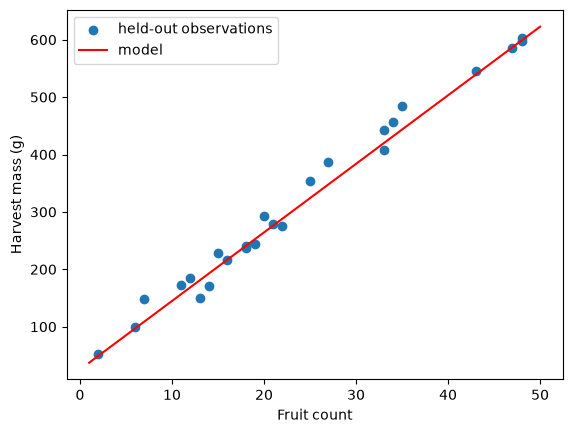

In [5]:
x_line = np.arange(1, 51).reshape(-1, 1)
plt.scatter(X_test[:, 0], y_test, label="held-out observations")
plt.plot(x_line[:, 0], model.predict(x_line), color="red", label="model")
plt.xlabel("Fruit count")
plt.ylabel("Harvest mass (g)")
plt.legend()
plt.show()

## Predict for new data

Save and reload as an example; temporary files disappear after this cell. Only load trusted joblib files. The star on the graph shows the new prediction alongside the fitted line and held-out observations.

Estimated mass for 20 fruit (g): 264.3


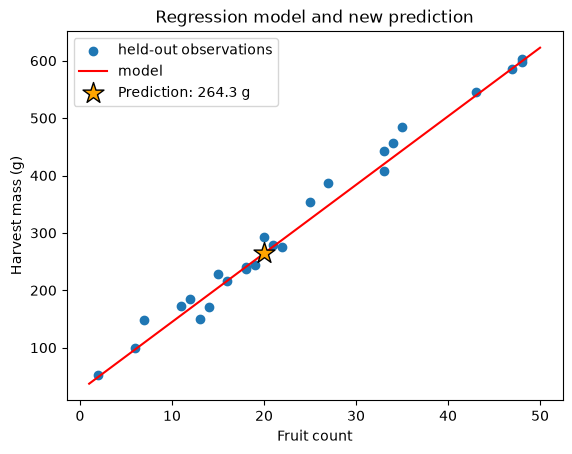

In [6]:
fruit_count = 20
with TemporaryDirectory() as folder:
    path = Path(folder) / "mass_model.joblib"
    joblib.dump(model, path)
    loaded_model = joblib.load(path)
    estimated_mass = loaded_model.predict([[fruit_count]])[0]
    print(f"Estimated mass for {fruit_count} fruit (g): {estimated_mass:.1f}")

plt.scatter(X_test[:, 0], y_test, label="held-out observations")
plt.plot(x_line[:, 0], loaded_model.predict(x_line), color="red", label="model")
plt.scatter(fruit_count, estimated_mass, marker="*", s=250, c="orange",
            edgecolors="black", label=f"Prediction: {estimated_mass:.1f} g", zorder=3)
plt.xlabel("Fruit count")
plt.ylabel("Harvest mass (g)")
plt.title("Regression model and new prediction")
plt.legend()
plt.show()

**Try:** In the first code cell, change `rng.normal(0, 20, size=len(X))` to `rng.normal(0, 50, size=len(X))`. The second number is the noise standard deviation in grams: increasing it makes observations more spread out. Run all cells again and compare the test mean absolute error and plots. You can also change `fruit_count = 20` in the prediction cell and rerun that cell. Avoid trusting predictions far outside the training range; real harvest weights need real measurements and an independent test set.